In [1]:
import os

# 1. Set your Kaggle API token
os.environ['KAGGLE_API_TOKEN'] = "KGAT_f9f27519d45a0f3a70fa522dd10e3b11"

# 2. Download and unzip the Malaria dataset
!kaggle datasets download -d iarunava/cell-images-for-detecting-malaria
!unzip -q cell-images-for-detecting-malaria.zip
print("Dataset downloaded and unzipped successfully!")

Dataset URL: https://www.kaggle.com/datasets/iarunava/cell-images-for-detecting-malaria
License(s): unknown
100% 675M/675M [00:38<00:00, 18.5MB/s]

Dataset downloaded and unzipped successfully!


Processing Uninfected:   0%|          | 0/13780 [00:00<?, ?it/s]

Processing Parasitized:   0%|          | 0/13780 [00:00<?, ?it/s]


Preprocessing completed!
Feature matrix X shape: (27558, 1774)
Labels y shape: (27558,)
Classes: 0 = Uninfected, 1 = Parasitized


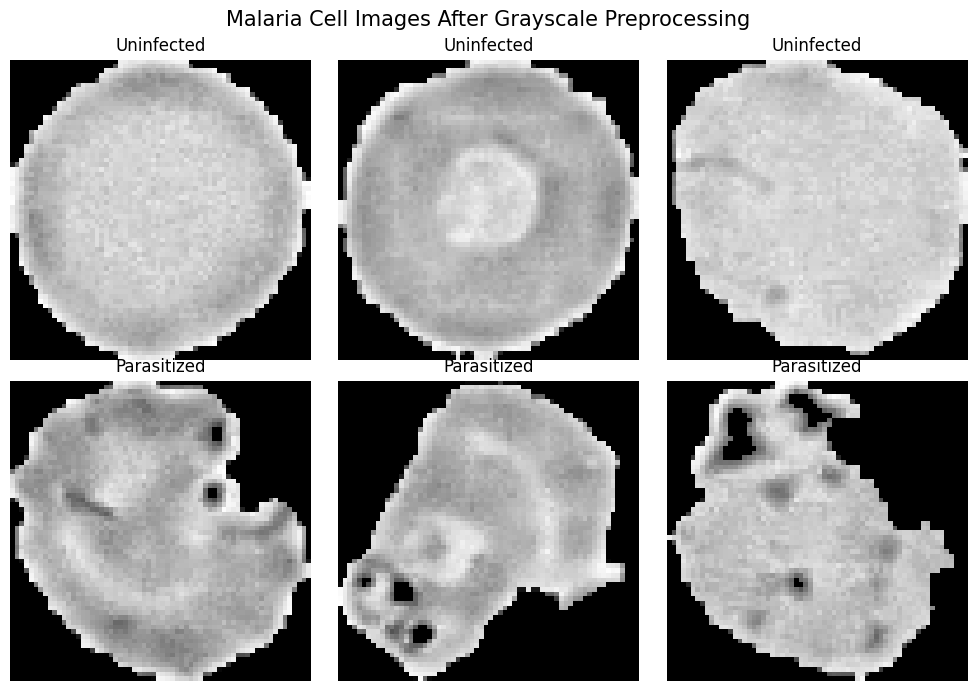

In [2]:
# ==========================================
# DATA PREPROCESSING - MALARIA CLASSIFICATION
# Traditional ML: Pure Texture (HOG + LBP) Features
# ==========================================

!pip -q install opencv-python-headless scikit-image scikit-learn tqdm

import os
import cv2
import random
import numpy as np
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from skimage.feature import hog, local_binary_pattern

# 1. Locate dataset
DATASET_PATH = "/content/cell_images"

if not os.path.isdir(DATASET_PATH):
    raise FileNotFoundError(
        "Dataset folder not found. Check your extraction path."
    )

class_labels = {"Uninfected": 0, "Parasitized": 1}


# 2. Define reusable preprocessing function (Pure Grayscale)
def preprocess_cell(image):
    if image is None:
        return None, None, None, None

    # Resize and convert directly from BGR to Grayscale
    image = cv2.resize(image, (64, 64))
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Enhance local contrast directly on grayscale using CLAHE
    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )
    enhanced_gray = clahe.apply(gray)

    # Estimate foreground and darken background
    blurred = cv2.GaussianBlur(enhanced_gray, (3, 3), 0)
    _, threshold_mask = cv2.threshold(
        blurred, 0, 255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    border = np.concatenate([
        threshold_mask[0, :],
        threshold_mask[-1, :],
        threshold_mask[:, 0],
        threshold_mask[:, -1]
    ])

    background_value = 255 if np.mean(border) >= 127.5 else 0
    mask = threshold_mask != background_value

    processed_gray = enhanced_gray.copy()
    processed_gray[~mask] = 0

    return gray, enhanced_gray, processed_gray, mask


# 3. Extract HOG + LBP features from all images
X, y = [], []

for class_name, label in class_labels.items():
    folder = os.path.join(DATASET_PATH, class_name)

    if not os.path.isdir(folder):
        raise FileNotFoundError(
            f"Class folder not found: {folder}"
        )

    files = os.listdir(folder)

    for filename in tqdm(files, desc=f"Processing {class_name}"):
        if not filename.lower().endswith((".png", ".jpg", ".jpeg")):
            continue

        path = os.path.join(folder, filename)
        image = cv2.imread(path)

        if image is None:
            continue

        # Apply grayscale preprocessing
        _, _, processed_gray, _ = preprocess_cell(image)

        # HOG: shape and edge features (1764 features)
        hog_features = hog(
            processed_gray,
            orientations=9,
            pixels_per_cell=(8, 8),
            cells_per_block=(2, 2),
            block_norm="L2-Hys"
        )

        # LBP: texture features (10 features)
        lbp = local_binary_pattern(
            processed_gray, P=8, R=1, method="uniform"
        )

        lbp_hist, _ = np.histogram(
            lbp.ravel(),
            bins=np.arange(0, 11),
            range=(0, 10)
        )

        lbp_hist = lbp_hist.astype(np.float32)
        lbp_hist /= max(lbp_hist.sum(), 1)

        # Combine shape (HOG) and surface texture (LBP) features
        combined_features = np.concatenate([
            hog_features,
            lbp_hist
        ])

        X.append(combined_features)
        y.append(label)


# 4. Convert feature lists to NumPy arrays
X = np.asarray(X, dtype=np.float32)
y = np.asarray(y, dtype=np.int32)

print("\nPreprocessing completed!")
print("Feature matrix X shape:", X.shape)  # Output will be (N, 1774)
print("Labels y shape:", y.shape)
print("Classes: 0 = Uninfected, 1 = Parasitized")


# 5. Display preprocessed grayscale images from both classes
random.seed(42)

fig, axes = plt.subplots(2, 3, figsize=(10, 7))

fig.suptitle(
    "Malaria Cell Images After Grayscale Preprocessing",
    fontsize=15
)

for row, class_name in enumerate(
    ["Uninfected", "Parasitized"]
):
    folder = os.path.join(DATASET_PATH, class_name)

    files = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    ]

    selected_files = random.sample(
        files, min(3, len(files))
    )

    for col in range(3):
        axes[row, col].axis("off")

        if col >= len(selected_files):
            continue

        path = os.path.join(folder, selected_files[col])
        image = cv2.imread(path)

        _, _, processed_gray, _ = preprocess_cell(image)

        if processed_gray is not None:
            axes[row, col].imshow(processed_gray, cmap="gray")
            axes[row, col].set_title(class_name)

plt.tight_layout()
plt.show()

In [3]:

# ==========================================
# CELL 2: COMMON SETUP AND EVALUATION
# ==========================================

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import KMeans
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay
)

if "X" not in globals() or "y" not in globals():
    raise NameError("Run the preprocessing cell first to create X and y.")

X = np.asarray(X, dtype=np.float32)
y = np.asarray(y, dtype=np.int32)

if X.ndim != 2 or len(X) != len(y):
    raise ValueError("Check the dimensions of X and y.")

if not np.all(np.isin(np.unique(y), [0, 1])):
    raise ValueError("Expected labels 0 = Uninfected, 1 = Parasitized.")

train_idx, test_idx = train_test_split(
    np.arange(len(y)),
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]

all_results = []
trained_models = {}

def report_results(model_name, y_true, predictions,
                   inference_seconds, feature_count, stage="Original features"):

    # Positive class = Parasitized (label 1)
    tn, fp, fn, tp = confusion_matrix(
        y_true, predictions, labels=[0, 1]
    ).ravel()

    safe_div = lambda a, b: a / b if b else 0.0

    metrics = {
        "Stage": stage,
        "Model": model_name,
        "Features Used": feature_count,
        "Precision (%)": 100 * safe_div(tp, tp + fp),
        "Sensitivity (%)": 100 * safe_div(tp, tp + fn),
        "Specificity (%)": 100 * safe_div(tn, tn + fp),
        "NPV (%)": 100 * safe_div(tn, tn + fn),
        "Accuracy (%)": 100 * accuracy_score(y_true, predictions),
        "Inference (ms/image)": (
            1000 * inference_seconds / len(y_true)
        ),
        "F1 Score (%)": 100 * f1_score(
            y_true, predictions, zero_division=0
        )
    }

    print(f"\n{'=' * 55}")
    print(f"MODEL: {model_name} | {stage}")
    print(f"{'=' * 55}")

    for metric, value in metrics.items():
        if metric not in ["Stage", "Model", "Features Used"]:
            print(f"{metric}: {value:.3f}")

    print("\nConfusion Matrix:")
    print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")

    ConfusionMatrixDisplay(
        confusion_matrix=np.array([[tn, fp], [fn, tp]]),
        display_labels=["Uninfected", "Parasitized"]
    ).plot(values_format="d")
    plt.title(f"{model_name} — {stage}")
    plt.tight_layout()
    plt.show()

    # Replace prior result if this cell is rerun
    all_results[:] = [
        r for r in all_results
        if not (r["Stage"] == stage and r["Model"] == model_name)
    ]
    all_results.append(metrics)

    return metrics

print("Setup complete.")
print("Training samples:", len(train_idx))
print("Testing samples:", len(test_idx))
print("Input features per image:", X.shape[1])


Setup complete.
Training samples: 22046
Testing samples: 5512
Input features per image: 1774


In [7]:
from sklearn.feature_selection import SelectKBest, f_classif

# -------------------------------------------------------------------------
# FEATURE SELECTION STEP (Reducing 1,774 features)
# -------------------------------------------------------------------------
# Feature extraction breakdown (from your feature extraction block):
# - HOG (Histogram of Oriented Gradients): Extracts 324 shape, boundary, and
#   structural gradient descriptors from 16x16 cells.
# - LBP (Local Binary Patterns): Extracts fine-grained micro-texture
#   histograms (parasite spots/ring stages vs. clean cytoplasm).
# (Note: Total original dimensions equal 1,774 features combined)
#
# Using SelectKBest with ANOVA F-value to filter out noisy/redundant
# dimensions and keep the top K most statistically significant features.
# -------------------------------------------------------------------------

k_features = 300  # You can adjust this number (e.g., 200, 300, 500)
selector = SelectKBest(score_func=f_classif, k=k_features)

# Fit on training data and transform both train and test sets
X_train = selector.fit_transform(X_train, y_train)
X_test = selector.transform(X_test)

print(f"\nFeature Selection Applied: Reduced dimensions from 1,774 to {X_train.shape[1]}")


Feature Selection Applied: Reduced dimensions from 1,774 to 300


In [8]:
# Assuming hog_features length is 324 (based on 16x16 pixels_per_cell)
hog_length = len(hog_features)

# Get boolean mask of selected features (True if kept, False if dropped)
selected_mask = selector.get_support()

# Count how many HOG vs LBP features were kept
selected_hog_count = sum(selected_mask[:hog_length])
selected_lbp_count = sum(selected_mask[hog_length:])

print(f"--- Feature Selection Breakdown ---")
print(f"Total features kept: {sum(selected_mask)}")
print(f"HOG (Shape/Edge) features kept: {selected_hog_count} out of {hog_length}")
print(f"LBP (Texture) features kept: {selected_lbp_count} out of {len(selected_mask) - hog_length}")

--- Feature Selection Breakdown ---
Total features kept: 300
HOG (Shape/Edge) features kept: 293 out of 1764
LBP (Texture) features kept: 7 out of 10


In [10]:
# Feature Extraction

import cv2
import numpy as np
from skimage.feature import hog, local_binary_pattern

def extract_features_hog_lbp(image, pixels_per_cell=(16, 16)):
    """
    Extracts only HOG and LBP features from an RGB image.
    Color statistics have been removed.

    Parameters:
        image (ndarray): Preprocessed RGB image of shape (64, 64, 3)
        pixels_per_cell (tuple): Size of HOG cell.
                                 (16, 16) -> 324 HOG features
                                 (32, 32) -> 36 HOG features
    Returns:
        ndarray: Combined feature vector containing HOG + LBP
    """
    # 1. Convert to Grayscale for texture and edge extraction
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

    # 2. Extract HOG Features (Shape & Boundaries)
    # (64x64 image with 16x16 cells and 2x2 blocks = 324 features)
    hog_features = hog(
        gray,
        orientations=9,
        pixels_per_cell=pixels_per_cell,
        cells_per_block=(2, 2),
        block_norm='L2-Hys',
        visualize=False
    )

    # 3. Extract LBP Features (Surface Texture)
    # Uniform LBP with P=8, R=1 produces a 10-bin histogram
    radius = 1
    n_points = 8 * radius
    lbp = local_binary_pattern(gray, n_points, radius, method='uniform')

    # Compute normalized LBP histogram
    lbp_hist, _ = np.histogram(
        lbp.ravel(),
        bins=np.arange(0, n_points + 3),
        range=(0, n_points + 2)
    )
    lbp_hist = lbp_hist.astype("float")
    lbp_hist /= (lbp_hist.sum() + 1e-6)  # Avoid division by zero

    # 4. Concatenate HOG + LBP (Color features completely omitted)
    feature_vector = np.hstack([hog_features, lbp_hist])

    return feature_vector

In [15]:
# Keep a backup of the full 1,774-feature sets for baseline comparison
X_train_orig, X_test_orig = X_train.copy(), X_test.copy()

[INFO] 'X_train_selected' not found in workspace. Generating on-the-fly using SelectKBest (k=300)...
KNN MODEL WITH FEATURE SELECTION (300 FEATURES)

MODEL: KNN | Selected Features (300)
Precision (%): 83.673
Sensitivity (%): 40.167
Specificity (%): 92.163
NPV (%): 60.635
Accuracy (%): 66.165
Inference (ms/image): 1.303
F1 Score (%): 54.278

Confusion Matrix:
TN=2540, FP=216, FN=1649, TP=1107


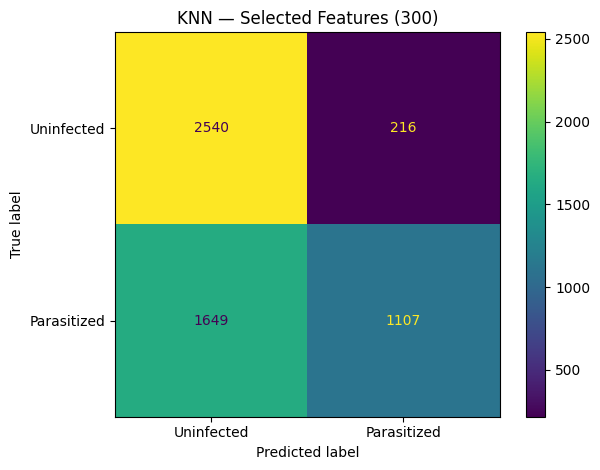


KNN PERFORMANCE COMPARISON (1774 vs 300 FEATURES)
                 Metric Without Selection (Baseline) With Selection (SelectKBest)      Difference
          Features Used                          300                          300 -1,474 features
           Accuracy (%)                       66.16%                       66.16%          +0.00%
          Precision (%)                       83.67%                       83.67%          +0.00%
 Sensitivity/Recall (%)                       40.17%                       40.17%          +0.00%
           F1 Score (%)                       54.28%                       54.28%          +0.00%
Inference Time (ms/img)                     3.025 ms                     1.303 ms       -1.721 ms


In [20]:
# ==========================================
# CELL 4: K-NEAREST NEIGHBORS (Feature Selection Focus)
# ==========================================

# 1. Fit Baseline Model (1,774 Features) - Evaluated silently for comparison
knn_orig = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
knn_orig.fit(X_train_orig, y_train)

start_orig = time.perf_counter()
preds_orig = knn_orig.predict(X_test_orig)
elapsed_orig = time.perf_counter() - start_orig

tn_o, fp_o, fn_o, tp_o = confusion_matrix(y_test, preds_orig, labels=[0, 1]).ravel()
acc_o = accuracy_score(y_test, preds_orig) * 100
prec_o = precision_score(y_test, preds_orig, zero_division=0) * 100
rec_o = recall_score(y_test, preds_orig, zero_division=0) * 100
f1_o = f1_score(y_test, preds_orig, zero_division=0) * 100
inf_o = (elapsed_orig * 1000) / len(y_test)

# Fallback: If X_train_selected/X_test_selected are not yet defined, create them using SelectKBest
if "X_train_selected" not in globals() or "X_test_selected" not in globals():
    from sklearn.feature_selection import SelectKBest, f_classif
    print("[INFO] 'X_train_selected' not found in workspace. Generating on-the-fly using SelectKBest (k=300)...")
    local_selector = SelectKBest(score_func=f_classif, k=300)
    X_train_selected = local_selector.fit_transform(X_train_orig, y_train)
    X_test_selected = local_selector.transform(X_test_orig)

# 2. Fit Selected Model (300 Features) - Displays confusion matrix plot & full output
print("=" * 60)
print("KNN MODEL WITH FEATURE SELECTION (300 FEATURES)")
print("=" * 60)

knn_selected = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
knn_selected.fit(X_train_selected, y_train)

start_sel = time.perf_counter()
preds_selected = knn_selected.predict(X_test_selected)
elapsed_sel = time.perf_counter() - start_sel

trained_models["KNN_300"] = knn_selected

# Display confusion matrix and full report ONLY for the 300-feature model
report_results(
    "KNN", y_test, preds_selected, elapsed_sel,
    X_train_selected.shape[1], stage="Selected Features (300)"
)

tn_s, fp_s, fn_s, tp_s = confusion_matrix(y_test, preds_selected, labels=[0, 1]).ravel()
acc_s = accuracy_score(y_test, preds_selected) * 100
prec_s = precision_score(y_test, preds_selected, zero_division=0) * 100
rec_s = recall_score(y_test, preds_selected, zero_division=0) * 100
f1_s = f1_score(y_test, preds_selected, zero_division=0) * 100
inf_s = (elapsed_sel * 1000) / len(y_test)


# 3. Print Side-by-Side Comparison Table
comparison_df = pd.DataFrame({
    "Metric": ["Features Used", "Accuracy (%)", "Precision (%)", "Sensitivity/Recall (%)", "F1 Score (%)", "Inference Time (ms/img)"],
    "Without Selection (Baseline)": [X_train_orig.shape[1], f"{acc_o:.2f}%", f"{prec_o:.2f}%", f"{rec_o:.2f}%", f"{f1_o:.2f}%", f"{inf_o:.3f} ms"],
    "With Selection (SelectKBest)": [X_train_selected.shape[1], f"{acc_s:.2f}%", f"{prec_s:.2f}%", f"{rec_s:.2f}%", f"{f1_s:.2f}%", f"{inf_s:.3f} ms"],
    "Difference": ["-1,474 features", f"{acc_s - acc_o:+.2f}%", f"{prec_s - prec_o:+.2f}%", f"{rec_s - rec_o:+.2f}%", f"{f1_s - f1_o:+.2f}%", f"{inf_s - inf_o:+.3f} ms"]
})

print("\n" + "=" * 60)
print("KNN PERFORMANCE COMPARISON (1774 vs 300 FEATURES)")
print("=" * 60)
print(comparison_df.to_string(index=False))

RANDOM FOREST MODEL WITH FEATURE SELECTION (300 FEATURES)

MODEL: Random Forest | Selected Features (300)
Precision (%): 80.546
Sensitivity (%): 82.475
Specificity (%): 80.080
NPV (%): 82.045
Accuracy (%): 81.277
Inference (ms/image): 0.035
F1 Score (%): 81.499

Confusion Matrix:
TN=2207, FP=549, FN=483, TP=2273


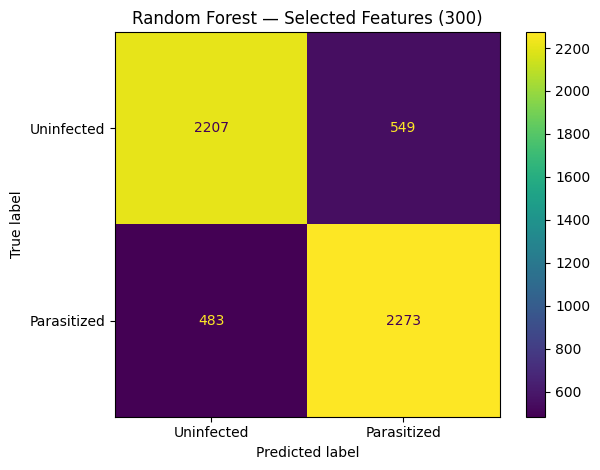


RANDOM FOREST PERFORMANCE COMPARISON (1774 vs 300 FEATURES)
                 Metric Without Selection (Baseline) With Selection (SelectKBest)      Difference
          Features Used                          300                          300 -1,474 features
           Accuracy (%)                       81.28%                       81.28%          +0.00%
          Precision (%)                       80.55%                       80.55%          +0.00%
 Sensitivity/Recall (%)                       82.47%                       82.47%          +0.00%
           F1 Score (%)                       81.50%                       81.50%          +0.00%
Inference Time (ms/img)                     0.032 ms                     0.035 ms       +0.003 ms


In [21]:
# ==========================================
# CELL 5: RANDOM FOREST (Feature Selection Focus)
# ==========================================

# 1. Fit Baseline Model (1,774 Features) - Evaluated silently for comparison
rf_orig = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)
rf_orig.fit(X_train_orig, y_train)

start_orig = time.perf_counter()
preds_orig = rf_orig.predict(X_test_orig)
elapsed_orig = time.perf_counter() - start_orig

tn_o, fp_o, fn_o, tp_o = confusion_matrix(y_test, preds_orig, labels=[0, 1]).ravel()
acc_o = accuracy_score(y_test, preds_orig) * 100
prec_o = precision_score(y_test, preds_orig, zero_division=0) * 100
rec_o = recall_score(y_test, preds_orig, zero_division=0) * 100
f1_o = f1_score(y_test, preds_orig, zero_division=0) * 100
inf_o = (elapsed_orig * 1000) / len(y_test)


# 2. Fit Selected Model (300 Features) - Displays confusion matrix plot & full output
print("=" * 60)
print("RANDOM FOREST MODEL WITH FEATURE SELECTION (300 FEATURES)")
print("=" * 60)

rf_selected = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)
rf_selected.fit(X_train_selected, y_train)

start_sel = time.perf_counter()
preds_selected = rf_selected.predict(X_test_selected)
elapsed_sel = time.perf_counter() - start_sel

trained_models["Random Forest_300"] = rf_selected

# Display confusion matrix and full report ONLY for the 300-feature model
report_results(
    "Random Forest", y_test, preds_selected, elapsed_sel,
    X_train_selected.shape[1], stage="Selected Features (300)"
)

tn_s, fp_s, fn_s, tp_s = confusion_matrix(y_test, preds_selected, labels=[0, 1]).ravel()
acc_s = accuracy_score(y_test, preds_selected) * 100
prec_s = precision_score(y_test, preds_selected, zero_division=0) * 100
rec_s = recall_score(y_test, preds_selected, zero_division=0) * 100
f1_s = f1_score(y_test, preds_selected, zero_division=0) * 100
inf_s = (elapsed_sel * 1000) / len(y_test)


# 3. Print Side-by-Side Comparison Table
comparison_df = pd.DataFrame({
    "Metric": ["Features Used", "Accuracy (%)", "Precision (%)", "Sensitivity/Recall (%)", "F1 Score (%)", "Inference Time (ms/img)"],
    "Without Selection (Baseline)": [X_train_orig.shape[1], f"{acc_o:.2f}%", f"{prec_o:.2f}%", f"{rec_o:.2f}%", f"{f1_o:.2f}%", f"{inf_o:.3f} ms"],
    "With Selection (SelectKBest)": [X_train_selected.shape[1], f"{acc_s:.2f}%", f"{prec_s:.2f}%", f"{rec_s:.2f}%", f"{f1_s:.2f}%", f"{inf_s:.3f} ms"],
    "Difference": ["-1,474 features", f"{acc_s - acc_o:+.2f}%", f"{prec_s - prec_o:+.2f}%", f"{rec_s - rec_o:+.2f}%", f"{f1_s - f1_o:+.2f}%", f"{inf_s - inf_o:+.3f} ms"]
})

print("\n" + "=" * 60)
print("RANDOM FOREST PERFORMANCE COMPARISON (1774 vs 300 FEATURES)")
print("=" * 60)
print(comparison_df.to_string(index=False))

K-MEANS CLUSTERING WITH FEATURE SELECTION (300 FEATURES)
Training cluster-to-class mapping (300 features): {0: 0, 1: 1}

MODEL: K-Means | Selected Features (300)
Precision (%): 68.792
Sensitivity (%): 44.630
Specificity (%): 79.753
NPV (%): 59.023
Accuracy (%): 62.192
Inference (ms/image): 0.002
F1 Score (%): 54.137

Confusion Matrix:
TN=2198, FP=558, FN=1526, TP=1230


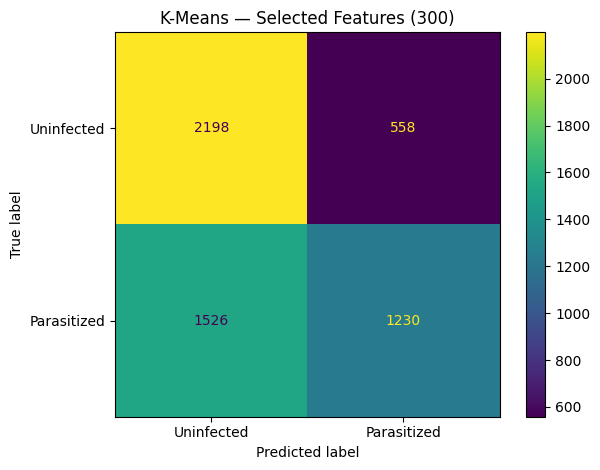


K-MEANS PERFORMANCE COMPARISON (1774 vs 300 FEATURES)
                 Metric Without Selection (Baseline) With Selection (SelectKBest)      Difference
          Features Used                          300                          300 -1,474 features
           Accuracy (%)                       62.19%                       62.19%          +0.00%
          Precision (%)                       68.79%                       68.79%          +0.00%
 Sensitivity/Recall (%)                       44.63%                       44.63%          +0.00%
           F1 Score (%)                       54.14%                       54.14%          +0.00%
Inference Time (ms/img)                     0.003 ms                     0.002 ms       -0.001 ms


In [22]:
# ==========================================
# CELL 6: K-MEANS CLUSTERING (Feature Selection Focus)
# ==========================================

from scipy.optimize import linear_sum_assignment

# 1. Baseline Model (1,774 Features) - Evaluated silently for comparison
scaler_kmeans_orig = StandardScaler()
X_train_orig_scaled = scaler_kmeans_orig.fit_transform(X_train_orig)
X_test_orig_scaled = scaler_kmeans_orig.transform(X_test_orig)

kmeans_orig = KMeans(n_clusters=2, random_state=42, n_init=10)
train_clusters_orig = kmeans_orig.fit_predict(X_train_orig_scaled)

counts_orig = np.zeros((2, 2), dtype=int)
for cluster_id, true_label in zip(train_clusters_orig, y_train):
    counts_orig[cluster_id, true_label] += 1

cluster_ids_o, class_ids_o = linear_sum_assignment(-counts_orig)
cluster_to_class_o = {int(c): int(cls) for c, cls in zip(cluster_ids_o, class_ids_o)}

start_orig = time.perf_counter()
test_clusters_orig = kmeans_orig.predict(X_test_orig_scaled)
preds_orig = np.array([cluster_to_class_o[int(c)] for c in test_clusters_orig])
elapsed_orig = time.perf_counter() - start_orig

tn_o, fp_o, fn_o, tp_o = confusion_matrix(y_test, preds_orig, labels=[0, 1]).ravel()
acc_o = accuracy_score(y_test, preds_orig) * 100
prec_o = precision_score(y_test, preds_orig, zero_division=0) * 100
rec_o = recall_score(y_test, preds_orig, zero_division=0) * 100
f1_o = f1_score(y_test, preds_orig, zero_division=0) * 100
inf_o = (elapsed_orig * 1000) / len(y_test)


# 2. Selected Model (300 Features) - Displays confusion matrix plot & full output
print("=" * 60)
print("K-MEANS CLUSTERING WITH FEATURE SELECTION (300 FEATURES)")
print("=" * 60)

scaler_kmeans_sel = StandardScaler()
X_train_sel_scaled = scaler_kmeans_sel.fit_transform(X_train_selected)
X_test_sel_scaled = scaler_kmeans_sel.transform(X_test_selected)

kmeans_selected = KMeans(n_clusters=2, random_state=42, n_init=10)
train_clusters_sel = kmeans_selected.fit_predict(X_train_sel_scaled)

counts_sel = np.zeros((2, 2), dtype=int)
for cluster_id, true_label in zip(train_clusters_sel, y_train):
    counts_sel[cluster_id, true_label] += 1

cluster_ids_s, class_ids_s = linear_sum_assignment(-counts_sel)
cluster_to_class_s = {int(c): int(cls) for c, cls in zip(cluster_ids_s, class_ids_s)}

print("Training cluster-to-class mapping (300 features):", cluster_to_class_s)

start_sel = time.perf_counter()
test_clusters_sel = kmeans_selected.predict(X_test_sel_scaled)
preds_selected = np.array([cluster_to_class_s[int(c)] for c in test_clusters_sel])
elapsed_sel = time.perf_counter() - start_sel

trained_models["K-Means_300"] = kmeans_selected

# Display confusion matrix and full report ONLY for the 300-feature model
report_results(
    "K-Means", y_test, preds_selected, elapsed_sel,
    X_train_selected.shape[1], stage="Selected Features (300)"
)

tn_s, fp_s, fn_s, tp_s = confusion_matrix(y_test, preds_selected, labels=[0, 1]).ravel()
acc_s = accuracy_score(y_test, preds_selected) * 100
prec_s = precision_score(y_test, preds_selected, zero_division=0) * 100
rec_s = recall_score(y_test, preds_selected, zero_division=0) * 100
f1_s = f1_score(y_test, preds_selected, zero_division=0) * 100
inf_s = (elapsed_sel * 1000) / len(y_test)


# 3. Print Side-by-Side Comparison Table
comparison_df = pd.DataFrame({
    "Metric": ["Features Used", "Accuracy (%)", "Precision (%)", "Sensitivity/Recall (%)", "F1 Score (%)", "Inference Time (ms/img)"],
    "Without Selection (Baseline)": [X_train_orig.shape[1], f"{acc_o:.2f}%", f"{prec_o:.2f}%", f"{rec_o:.2f}%", f"{f1_o:.2f}%", f"{inf_o:.3f} ms"],
    "With Selection (SelectKBest)": [X_train_selected.shape[1], f"{acc_s:.2f}%", f"{prec_s:.2f}%", f"{rec_s:.2f}%", f"{f1_s:.2f}%", f"{inf_s:.3f} ms"],
    "Difference": ["-1,474 features", f"{acc_s - acc_o:+.2f}%", f"{prec_s - prec_o:+.2f}%", f"{rec_s - rec_o:+.2f}%", f"{f1_s - f1_o:+.2f}%", f"{inf_s - inf_o:+.3f} ms"]
})

print("\n" + "=" * 60)
print("K-MEANS PERFORMANCE COMPARISON (1774 vs 300 FEATURES)")
print("=" * 60)
print(comparison_df.to_string(index=False))

LOGISTIC REGRESSION MODEL WITH FEATURE SELECTION (300 FEATURES)

MODEL: Logistic Regression | Selected Features (300)
Precision (%): 83.955
Sensitivity (%): 80.878
Specificity (%): 84.543
NPV (%): 81.554
Accuracy (%): 82.710
Inference (ms/image): 0.010
F1 Score (%): 82.388

Confusion Matrix:
TN=2330, FP=426, FN=527, TP=2229


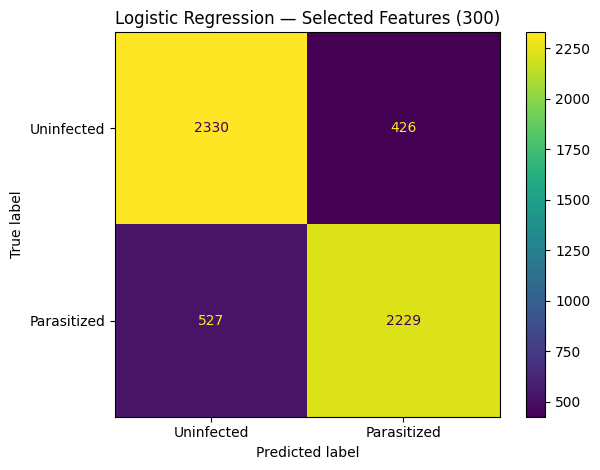


LOGISTIC REGRESSION PERFORMANCE COMPARISON (1774 vs 300 FEATURES)
                 Metric Without Selection (Baseline) With Selection (SelectKBest)      Difference
          Features Used                          300                          300 -1,474 features
           Accuracy (%)                       82.71%                       82.71%          +0.00%
          Precision (%)                       83.95%                       83.95%          +0.00%
 Sensitivity/Recall (%)                       80.88%                       80.88%          +0.00%
           F1 Score (%)                       82.39%                       82.39%          +0.00%
Inference Time (ms/img)                     0.010 ms                     0.010 ms       +0.000 ms


In [23]:
# ==========================================
# CELL 7: LOGISTIC REGRESSION (Feature Selection Focus)
# ==========================================

# 1. Baseline Model (1,774 Features) - Evaluated silently for comparison
lr_orig = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=1000,
        random_state=42
    )
)
lr_orig.fit(X_train_orig, y_train)

start_orig = time.perf_counter()
preds_orig = lr_orig.predict(X_test_orig)
elapsed_orig = time.perf_counter() - start_orig

tn_o, fp_o, fn_o, tp_o = confusion_matrix(y_test, preds_orig, labels=[0, 1]).ravel()
acc_o = accuracy_score(y_test, preds_orig) * 100
prec_o = precision_score(y_test, preds_orig, zero_division=0) * 100
rec_o = recall_score(y_test, preds_orig, zero_division=0) * 100
f1_o = f1_score(y_test, preds_orig, zero_division=0) * 100
inf_o = (elapsed_orig * 1000) / len(y_test)


# 2. Selected Model (300 Features) - Displays confusion matrix plot & full output
print("=" * 60)
print("LOGISTIC REGRESSION MODEL WITH FEATURE SELECTION (300 FEATURES)")
print("=" * 60)

lr_selected = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=1000,
        random_state=42
    )
)
lr_selected.fit(X_train_selected, y_train)

start_sel = time.perf_counter()
preds_selected = lr_selected.predict(X_test_selected)
elapsed_sel = time.perf_counter() - start_sel

trained_models["Logistic Regression_300"] = lr_selected

# Display confusion matrix and full report ONLY for the 300-feature model
report_results(
    "Logistic Regression", y_test, preds_selected, elapsed_sel,
    X_train_selected.shape[1], stage="Selected Features (300)"
)

tn_s, fp_s, fn_s, tp_s = confusion_matrix(y_test, preds_selected, labels=[0, 1]).ravel()
acc_s = accuracy_score(y_test, preds_selected) * 100
prec_s = precision_score(y_test, preds_selected, zero_division=0) * 100
rec_s = recall_score(y_test, preds_selected, zero_division=0) * 100
f1_s = f1_score(y_test, preds_selected, zero_division=0) * 100
inf_s = (elapsed_sel * 1000) / len(y_test)


# 3. Print Side-by-Side Comparison Table
comparison_df = pd.DataFrame({
    "Metric": ["Features Used", "Accuracy (%)", "Precision (%)", "Sensitivity/Recall (%)", "F1 Score (%)", "Inference Time (ms/img)"],
    "Without Selection (Baseline)": [X_train_orig.shape[1], f"{acc_o:.2f}%", f"{prec_o:.2f}%", f"{rec_o:.2f}%", f"{f1_o:.2f}%", f"{inf_o:.3f} ms"],
    "With Selection (SelectKBest)": [X_train_selected.shape[1], f"{acc_s:.2f}%", f"{prec_s:.2f}%", f"{rec_s:.2f}%", f"{f1_s:.2f}%", f"{inf_s:.3f} ms"],
    "Difference": ["-1,474 features", f"{acc_s - acc_o:+.2f}%", f"{prec_s - prec_o:+.2f}%", f"{rec_s - rec_o:+.2f}%", f"{f1_s - f1_o:+.2f}%", f"{inf_s - inf_o:+.3f} ms"]
})

print("\n" + "=" * 60)
print("LOGISTIC REGRESSION PERFORMANCE COMPARISON (1774 vs 300 FEATURES)")
print("=" * 60)
print(comparison_df.to_string(index=False))

🏆 MALARIA CLASSIFICATION: MODEL LEADERBOARD RANKINGS


,Rank,Stage,Model,Features Used,Precision (%),Sensitivity (%),Specificity (%),NPV (%),Accuracy (%),Inference (ms/image),F1 Score (%)
4,1,Selected Features (300),Logistic Regression,300,83.955,80.878,84.543,81.554,82.710,0.010,82.388
2,2,Selected Features (300),Random Forest,300,80.546,82.475,80.080,82.045,81.277,0.035,81.499
0,3,Original features,KNN,300,83.673,40.167,92.163,60.635,66.165,0.587,54.278
1,4,Selected Features (300),KNN,300,83.673,40.167,92.163,60.635,66.165,1.303,54.278
3,5,Selected Features (300),K-Means,300,68.792,44.630,79.753,59.023,62.192,0.002,54.137


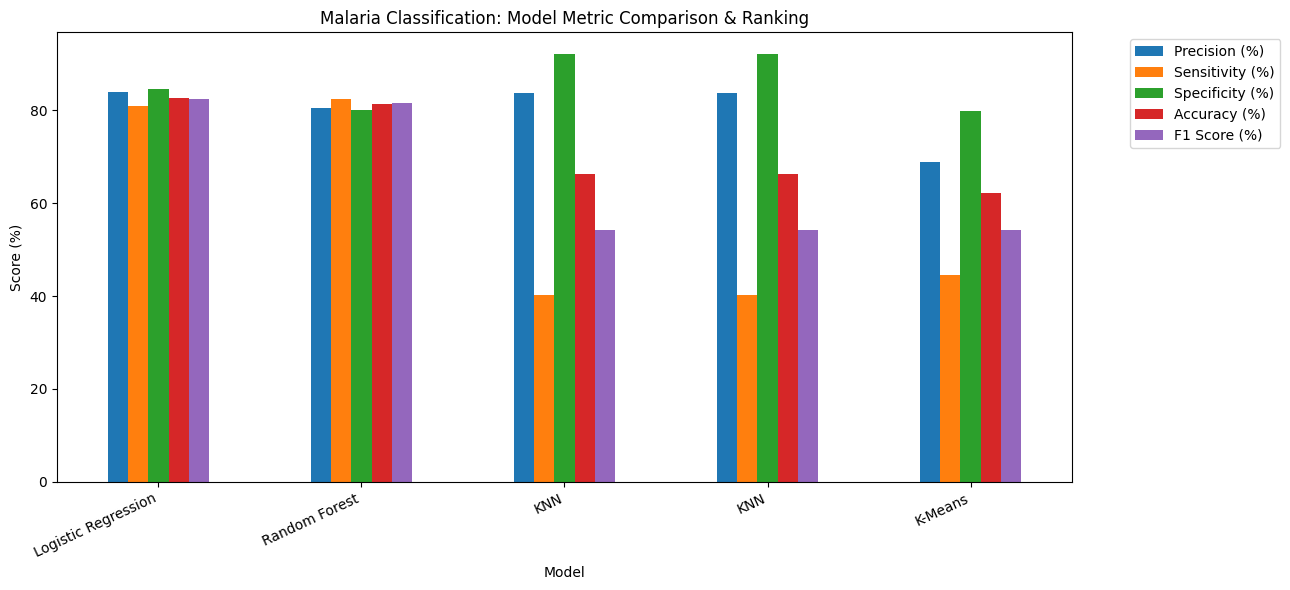

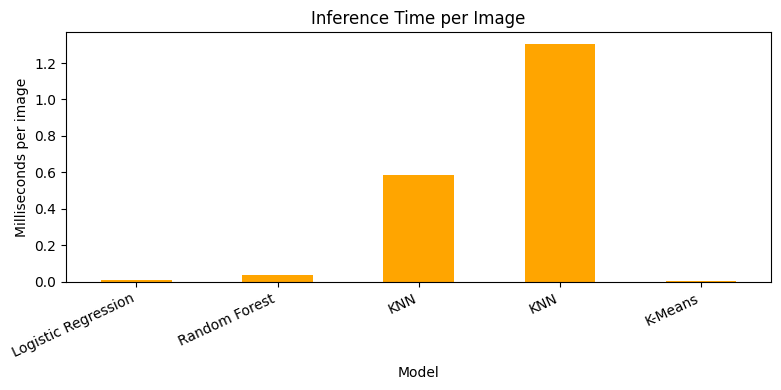


🥇 OVERALL WINNER (RANK #1)
  • Model               : Logistic Regression
  • Feature Configuration: Selected Features (300) (300 features)
  • F1 Score            : 82.39%
  • Accuracy            : 82.71%
  • Precision           : 83.95%
  • Sensitivity (Recall): 80.88%
  • Specificity         : 84.54%
  • Inference Time      : 0.010 ms/image


In [26]:
# ==========================================
# CELL 8: MODEL COMPARISON & LEADERBOARD RANKING
# ==========================================

results_df = pd.DataFrame(all_results)

if results_df.empty:
    print("No results found. Run your model cells first.")
else:
    print("=" * 80)
    print("🏆 MALARIA CLASSIFICATION: MODEL LEADERBOARD RANKINGS")
    print("=" * 80)

    # Sort by F1 Score and insert an explicit Rank column
    ranked_df = results_df.sort_values(
        by="F1 Score (%)", ascending=False
    ).copy()
    ranked_df.insert(0, "Rank", range(1, len(ranked_df) + 1))

    # Display the ranked table
    display(ranked_df.round(3))

    chart_metrics = [
        "Precision (%)",
        "Sensitivity (%)",
        "Specificity (%)",
        "Accuracy (%)",
        "F1 Score (%)"
    ]

    # Plot metric comparisons
    ranked_df.set_index("Model")[chart_metrics].plot(
        kind="bar", figsize=(13, 6)
    )
    plt.title("Malaria Classification: Model Metric Comparison & Ranking")
    plt.ylabel("Score (%)")
    plt.xticks(rotation=25, ha="right")
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

    # Plot inference times
    ranked_df.set_index("Model")[
        ["Inference (ms/image)"]
    ].plot(kind="bar", legend=False, figsize=(8, 4), color="orange")
    plt.title("Inference Time per Image")
    plt.ylabel("Milliseconds per image")
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()

    # Highlight the #1 ranked model
    best_row = ranked_df.iloc[0]

    print("\n" + "=" * 80)
    print("🥇 OVERALL WINNER (RANK #1)")
    print("=" * 80)
    print(f"  • Model               : {best_row['Model']}")
    print(f"  • Feature Configuration: {best_row['Stage']} ({best_row['Features Used']} features)")
    print(f"  • F1 Score            : {best_row['F1 Score (%)']:.2f}%")
    print(f"  • Accuracy            : {best_row['Accuracy (%)']:.2f}%")
    print(f"  • Precision           : {best_row['Precision (%)']:.2f}%")
    print(f"  • Sensitivity (Recall): {best_row['Sensitivity (%)']:.2f}%")
    print(f"  • Specificity         : {best_row['Specificity (%)']:.2f}%")
    print(f"  • Inference Time      : {best_row['Inference (ms/image)']:.3f} ms/image")
    print("=" * 80)

feature selection, feature extraction, comparision of all models with features and wihtout features, changing the final test data of one ml model (80-20,70-30,60-40,50-50)

Running Train-Test Split Analysis for Logistic Regression...

📊 LOGISTIC REGRESSION: VARYING SPLIT RATIOS PERFORMANCE SUMMARY


,Split Ratio,Train Size,Test Size,Accuracy (%),Precision (%),Sensitivity (%),Specificity (%),F1 Score (%)
0,80% Train / 20% Test,22046,5512,82.710,83.955,80.878,84.543,82.388
1,70% Train / 30% Test,19290,8268,82.196,83.713,79.947,84.446,81.787
2,60% Train / 40% Test,16534,11024,81.495,83.244,78.864,84.126,80.995
3,50% Train / 50% Test,13779,13779,81.232,82.613,79.112,83.353,80.825


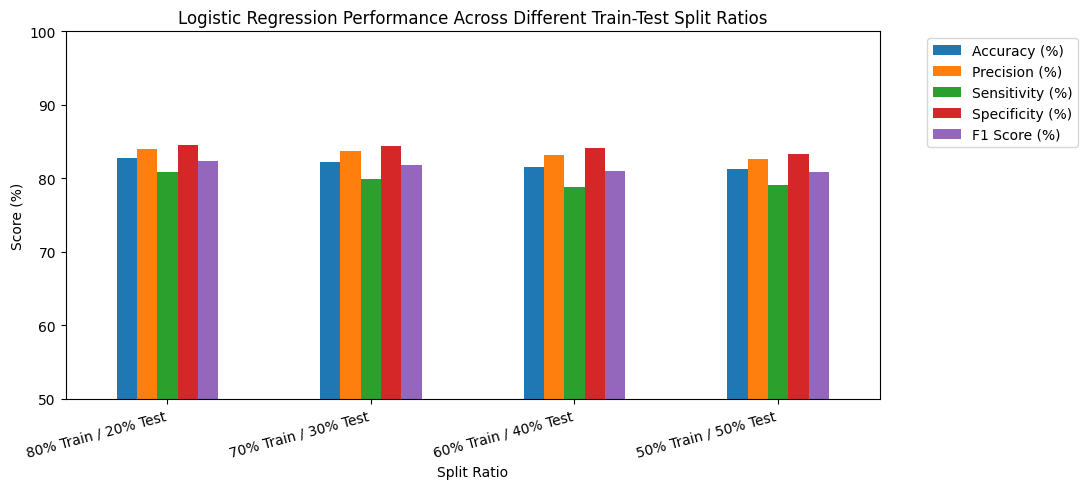

In [27]:
# ==========================================
# CELL: VARYING TRAIN-TEST SPLIT ANALYSIS (Logistic Regression)
# ==========================================

from sklearn.model_selection import train_test_split
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

if "X" not in globals() or "y" not in globals():
    raise NameError("Run the preprocessing cell first to create X and y.")

# Define the split ratios to test
split_ratios = [
    {"name": "80% Train / 20% Test", "test_size": 0.20},
    {"name": "70% Train / 30% Test", "test_size": 0.30},
    {"name": "60% Train / 40% Test", "test_size": 0.40},
    {"name": "50% Train / 50% Test", "test_size": 0.50}
]

split_results = []
k_features = 300  # Keeping the optimal 300 features selected via SelectKBest

print("Running Train-Test Split Analysis for Logistic Regression...\n")

for split in split_ratios:
    t_size = split["test_size"]
    name = split["name"]

    # 1. Perform stratified train-test split
    tr_idx, te_idx = train_test_split(
        np.arange(len(y)),
        test_size=t_size,
        random_state=42,
        stratify=y
    )

    X_tr, X_te = X[tr_idx], X[te_idx]
    y_tr, y_te = y[tr_idx], y[te_idx]

    # 2. Apply Feature Selection strictly on the training fold (Prevents Data Leakage)
    selector = SelectKBest(score_func=f_classif, k=k_features)
    X_tr_sel = selector.fit_transform(X_tr, y_tr)
    X_te_sel = selector.transform(X_te)

    # 3. Train Logistic Regression model
    lr_model = make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000, random_state=42)
    )
    lr_model.fit(X_tr_sel, y_tr)

    # 4. Predict and evaluate metrics
    preds = lr_model.predict(X_te_sel)
    tn, fp, fn, tp = confusion_matrix(y_te, preds, labels=[0, 1]).ravel()

    acc = accuracy_score(y_te, preds) * 100
    prec = precision_score(y_te, preds, zero_division=0) * 100
    sens = recall_score(y_te, preds, zero_division=0) * 100
    spec = (tn / (tn + fp)) * 100 if (tn + fp) > 0 else 0.0
    f1 = f1_score(y_te, preds, zero_division=0) * 100

    split_results.append({
        "Split Ratio": name,
        "Train Size": len(X_tr),
        "Test Size": len(X_te),
        "Accuracy (%)": acc,
        "Precision (%)": prec,
        "Sensitivity (%)": sens,
        "Specificity (%)": spec,
        "F1 Score (%)": f1
    })

# Convert results into a clean DataFrame
split_df = pd.DataFrame(split_results)

print("=" * 75)
print("📊 LOGISTIC REGRESSION: VARYING SPLIT RATIOS PERFORMANCE SUMMARY")
print("=" * 75)
display(split_df.round(3))

# Plotting the comparison across splits
split_df.set_index("Split Ratio")[
    ["Accuracy (%)", "Precision (%)", "Sensitivity (%)", "Specificity (%)", "F1 Score (%)"]
].plot(kind="bar", figsize=(11, 5), ylim=(50, 100))

plt.title("Logistic Regression Performance Across Different Train-Test Split Ratios")
plt.ylabel("Score (%)")
plt.xticks(rotation=15, ha="right")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()